In [87]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

**CONFIGURATION**

In [88]:
CSV_PATH = "/Users/hariharajujjarapu/Desktop/Learnings/pytorch-learning/Berlin_wind_multiclass 1(in).csv"
TARGET_COLUMN = "X50Hertz..MW."

N_CLIENTS = 5
MAX_BINS = 64
N_PERCENTILES = 101

N_ESTIMATORS = 750
MAX_DEPTH = 5
ETA = 0.3

LAMBDA = 1.0
GAMMA = 0.0
MIN_CHILD_WEIGHT = 1.0
MIN_SPLIT_LOSS = GAMMA

SEED = 42
N_CLASSES = 5

**1. DATA AND FIVE-CLASS TARGET**

In [89]:
def load_data():
    df = pd.read_csv(CSV_PATH)

    target = 'X50Hertz..MW.'

    df['target'] = pd.qcut(
        df[target].rank(method='first'),
        q=5,
        labels=[0, 1, 2, 3, 4]
    ).astype(int)

    print(df['target'].value_counts().sort_index())

    df.drop(columns=['X50Hertz..MW.'], inplace=True)
    df = df.sample(frac=1, random_state=42).reset_index(drop=True)

    y = df['target'].to_numpy(dtype=np.int32)
    Xdf = df.drop(columns=['target'])

    if len(Xdf.select_dtypes(exclude=np.number).columns):
        raise ValueError("Encode non-numeric features before training.")

    Xdf = Xdf.replace([np.inf, -np.inf], np.nan)
    X = Xdf.to_numpy(dtype=np.float64)

    if np.isnan(X).all(axis=0).any():
        raise ValueError("A feature contains only missing values.")

    return X, y, Xdf.columns.tolist()

In [90]:
def split_data(X, y):
    X_train, X_tmp, y_train, y_tmp = train_test_split(
        X, y, test_size=0.30, random_state=SEED, stratify=y
    )

    X_val, X_test, y_val, y_test = train_test_split(
        X_tmp, y_tmp, test_size=0.50,
        random_state=SEED, stratify=y_tmp
    )

    # Fit imputation on training data only.
    medians = np.nanmedian(X_train, axis=0)
    medians = np.where(np.isnan(medians), 0.0, medians)

    def impute(A):
        return np.where(np.isnan(A), medians[None, :], A)

    return (
        impute(X_train), impute(X_val), impute(X_test),
        y_train, y_val, y_test, medians
    )

In [91]:
def select_features_by_correlation(
    X_train, X_val, X_test,
    y_train, feature_names,
    threshold=0.05
):
    # Convert training data into DataFrame
    X_train_df = pd.DataFrame(
        X_train, columns=feature_names
    )

    X_train_df['target'] = y_train

    # Calculate correlation with target
    corr_target = X_train_df.corr(numeric_only=True)['target']

    # Identify features with correlation between -0.05 and +0.05
    features_to_remove = corr_target[
        (corr_target >= -threshold) &
        (corr_target <= threshold) &
        (corr_target.index != 'target')
    ].index.tolist()

    # Retain remaining features
    selected_features = [
        col for col in feature_names
        if col not in features_to_remove
    ]

    if not selected_features:
        raise ValueError("No features remaining after feature selection.")

    print("\nFeatures removed:", features_to_remove)
    print("Features retained:", selected_features)

    # Get corresponding column indices
    selected_indices = [
        feature_names.index(col)
        for col in selected_features
    ]

    # Apply the same feature selection to all datasets
    X_train = X_train[:, selected_indices]
    X_val = X_val[:, selected_indices]
    X_test = X_test[:, selected_indices]

    return X_train, X_val, X_test, selected_features

**2. SIMULATED CLIENTS**

In [92]:
def make_clients(X, y, n_clients=5):
    rng = np.random.default_rng(SEED)
    partitions = [[] for _ in range(n_clients)]

    # Stratified partition: approximately equal class proportions.
    for cls in np.unique(y):
        idx = np.flatnonzero(y == cls)
        rng.shuffle(idx)

        for k, part in enumerate(np.array_split(idx, n_clients)):
            partitions[k].extend(part.tolist())

    clients = []
    for idx in partitions:
        idx = np.asarray(idx, dtype=int)
        rng.shuffle(idx)
        clients.append((X[idx], y[idx]))

    return clients

**3. CLIENT SUMMARIES -> SERVER COMMON BINS**

In [93]:
def summarize_client_features(X, n_percentiles=101):
    q = np.linspace(0, 100, n_percentiles)
    result = []

    for j in range(X.shape[1]):
        x = X[:, j]
        result.append({
            "min": np.min(x),
            "max": np.max(x),
            "percentiles": np.percentile(x, q),
            "n": len(x)
        })

    return result

In [94]:
def weighted_quantile(values, weights, quantiles):
    order = np.argsort(values)
    values = np.asarray(values)[order]
    weights = np.asarray(weights)[order]

    cumulative = np.cumsum(weights)
    cdf = (cumulative - 0.5 * weights) / cumulative[-1]

    return np.interp(
        quantiles, cdf, values,
        left=values[0], right=values[-1]
    )

In [95]:
def server_build_bins(client_summaries, n_features, max_bins=64):
    """
    Approximate common global quantile bins from client summaries.
    The server sends the resulting edges to all clients.
    """
    bin_quantiles = np.linspace(0, 1, max_bins + 1)[1:-1]
    edges = []

    for j in range(n_features):
        values, weights = [], []
        global_min, global_max = np.inf, -np.inf

        for summary in client_summaries:
            s = summary[j]
            global_min = min(global_min, s["min"])
            global_max = max(global_max, s["max"])

            # Approximate weights for the client's reported quantiles.
            n_points = len(s["percentiles"])
            values.extend(s["percentiles"])
            weights.extend([s["n"] / n_points] * n_points)

        if global_min == global_max:
            feature_edges = np.array([], dtype=float)
        else:
            feature_edges = weighted_quantile(
                values, weights, bin_quantiles
            )
            feature_edges = np.unique(feature_edges)
            feature_edges = feature_edges[
                (feature_edges > global_min)
                & (feature_edges < global_max)
            ]

        edges.append(feature_edges)

    return edges

In [96]:
def bin_features(X, edges):
    B = np.empty(X.shape, dtype=np.int32)

    for j, e in enumerate(edges):
        B[:, j] = np.searchsorted(e, X[:, j], side="left")

    return B

**4. MULTICLASS OBJECTIVE: GRADIENTS AND HESSIANS**

In [97]:
def softmax(scores):
    scores = scores - scores.max(axis=1, keepdims=True)
    exp_scores = np.exp(scores)
    return exp_scores / exp_scores.sum(axis=1, keepdims=True)

In [98]:
def calc_grad_hess(scores, y, class_id):
    """
    Multiclass softmax objective with diagonal Hessian approximation.
    """
    p = softmax(scores)[:, class_id]
    g = p - (y == class_id).astype(float)
    h = p * (1.0 - p)

    return g, h

**5. XGBOOST REGULARIZATION AND SPLIT GAIN**

In [99]:
def calc_weight(G, H):
    # L1 regularization alpha is zero in this configuration.
    return -G / (H + LAMBDA)

In [100]:
def calc_score(G, H):
    # Negative twice the regularized leaf objective, up to constants.
    return G * G / (H + LAMBDA)

In [101]:
def calc_gain(GL, HL, GR, HR, G, H):
    return 0.5 * (
        calc_score(GL, HL)
        + calc_score(GR, HR)
        - calc_score(G, H)
    ) - MIN_SPLIT_LOSS

**6. LOCAL HISTOGRAMS AND SERVER AGGREGATION**

In [102]:
def local_histogram(B, indices, g, h, feature, n_bins):
    ids = B[indices, feature]

    G_hist = np.bincount(
        ids, weights=g[indices], minlength=n_bins
    ).astype(float)

    H_hist = np.bincount(
        ids, weights=h[indices], minlength=n_bins
    ).astype(float)

    return G_hist, H_hist

In [103]:
def aggregate_histograms(
    client_bins, node_indices, client_g, client_h,
    feature, edges
):
    """
    Each client sends local G/H histograms.
    Server sums corresponding bins.
    """
    n_bins = len(edges[feature]) + 1

    G_total = np.zeros(n_bins, dtype=float)
    H_total = np.zeros(n_bins, dtype=float)

    for k, B in enumerate(client_bins):
        Gk, Hk = local_histogram(
            B, node_indices[k], client_g[k], client_h[k],
            feature, n_bins
        )
        G_total += Gk
        H_total += Hk

    return G_total, H_total

**7. DISTRIBUTED TREE GROWTH**

In [104]:
def build_tree(clients, client_bins, client_g, client_h, edges):
    n_features = client_bins[0].shape[1]

    root_indices = [
        np.arange(len(y)) for _, y in clients
    ]

    def grow(indices_by_client, depth):
        G = sum(
            client_g[k][idx].sum()
            for k, idx in enumerate(indices_by_client)
        )
        H = sum(
            client_h[k][idx].sum()
            for k, idx in enumerate(indices_by_client)
        )

        leaf_weight = calc_weight(G, H)

        if depth >= MAX_DEPTH:
            return {"leaf": leaf_weight}

        best_gain = 0.0
        best_feature = None
        best_bin = None

        for feature in range(n_features):
            G_hist, H_hist = aggregate_histograms(
                client_bins, indices_by_client,
                client_g, client_h, feature, edges
            )

            cum_G = np.cumsum(G_hist)
            cum_H = np.cumsum(H_hist)

            for b in range(len(edges[feature])):
                GL, HL = cum_G[b], cum_H[b]
                GR, HR = G - GL, H - HL

                # XGBoost-style child Hessian constraint.
                if HL < MIN_CHILD_WEIGHT or HR < MIN_CHILD_WEIGHT:
                    continue

                gain = calc_gain(GL, HL, GR, HR, G, H)

                if gain > best_gain:
                    best_gain = gain
                    best_feature = feature
                    best_bin = b

        if best_feature is None:
            return {"leaf": leaf_weight}

        left_idx, right_idx = [], []

        # All clients apply the server-selected split.
        for k, B in enumerate(client_bins):
            idx = indices_by_client[k]
            goes_left = B[idx, best_feature] <= best_bin

            left_idx.append(idx[goes_left])
            right_idx.append(idx[~goes_left])

        return {
            "feature": best_feature,
            "split_bin": best_bin,
            "gain": best_gain,
            "left": grow(left_idx, depth + 1),
            "right": grow(right_idx, depth + 1)
        }

    return grow(root_indices, 0)

In [105]:
def predict_tree(tree, B):
    out = np.zeros(len(B), dtype=float)

    def visit(node, idx):
        if len(idx) == 0:
            return

        if "leaf" in node:
            out[idx] = node["leaf"]
            return

        f, b = node["feature"], node["split_bin"]
        left = B[idx, f] <= b

        visit(node["left"], idx[left])
        visit(node["right"], idx[~left])

    visit(tree, np.arange(len(B)))
    return out

**8. FEDERATED XGBOOST-STYLE MULTICLASS BOOSTING**

In [106]:
class FederatedXGBoost:
    def __init__(self, n_estimators=750):
        self.n_estimators = n_estimators
        self.edges = None
        self.trees = []
        self.base_scores = np.zeros(N_CLASSES)

    def fit(self, clients, edges):
        self.edges = edges

        client_bins = [
            bin_features(X, edges) for X, _ in clients
        ]

        # Use uniform initial class probabilities.
        self.base_scores = np.zeros(N_CLASSES, dtype=float)

        client_scores = [
            np.tile(self.base_scores, (len(y), 1))
            for _, y in clients
        ]

        start = time.time()

        for iteration in range(self.n_estimators):
            # Freeze predictions for this boosting round.
            round_scores = [s.copy() for s in client_scores]
            round_trees = []

            for class_id in range(N_CLASSES):
                derivs = [
                    calc_grad_hess(
                        round_scores[k], clients[k][1], class_id
                    )
                    for k in range(len(clients))
                ]

                client_g = [d[0] for d in derivs]
                client_h = [d[1] for d in derivs]

                tree = build_tree(
                    clients, client_bins,
                    client_g, client_h, edges
                )
                round_trees.append(tree)

            # Apply the class-specific trees after building the round.
            for k in range(len(clients)):
                for c, tree in enumerate(round_trees):
                    client_scores[k][:, c] += ETA * predict_tree(
                        tree, client_bins[k]
                    )

            self.trees.append(round_trees)

            if (iteration + 1) % 10 == 0:
                print(f"Boosting round {iteration + 1}")

        print(f"Training time: {time.time() - start:.2f}s")
        return self

    def predict_proba(self, X):
        B = bin_features(X, self.edges)
        scores = np.tile(self.base_scores, (len(X), 1))

        for round_trees in self.trees:
            for c, tree in enumerate(round_trees):
                scores[:, c] += ETA * predict_tree(tree, B)

        return softmax(scores)

    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)

**9. RUN**

target
0    14016
1    14016
2    14016
3    14016
4    14016
Name: count, dtype: int64

Features removed: ['Year', 'Day', 'Hour', 'Minute', 'Fill.Flag', 'Surface.Albedo']
Features retained: ['Month', 'Temperature', 'Clearsky.DHI', 'Clearsky.DNI', 'Clearsky.GHI', 'Cloud.Type', 'Dew.Point', 'DHI', 'DNI', 'GHI', 'Ozone', 'Relative.Humidity', 'Solar.Zenith.Angle', 'Pressure', 'Precipitable.Water', 'Wind.Direction', 'Wind.Speed']

Number of features after selection: 17

Client sizes: [9815, 9811, 9810, 9810, 9810]
Shared bins created and ready for clients.
Boosting round 10
Boosting round 20
Boosting round 30
Boosting round 40
Boosting round 50
Boosting round 60
Boosting round 70
Boosting round 80
Boosting round 90
Boosting round 100
Boosting round 110
Boosting round 120
Boosting round 130
Boosting round 140
Boosting round 150
Boosting round 160
Boosting round 170
Boosting round 180
Boosting round 190
Boosting round 200
Boosting round 210
Boosting round 220
Boosting round 230
Boosting roun

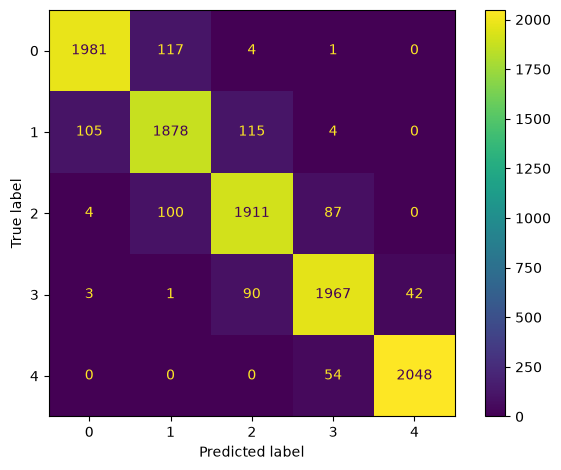

In [107]:
def main():
    X, y, feature_names = load_data()

    (
        X_train, X_val, X_test,
        y_train, y_val, y_test, medians
    ) = split_data(X, y)

    # Feature Selection using Correlation
    X_train, X_val, X_test, feature_names = select_features_by_correlation(
        X_train, X_val, X_test,
        y_train, feature_names,
        threshold=0.05
    )

    print("\nNumber of features after selection:", len(feature_names))

    clients = make_clients(X_train, y_train, N_CLIENTS)

    print("\nClient sizes:", [len(yc) for _, yc in clients])

    # Client -> server: feature summaries.
    summaries = [
        summarize_client_features(Xc, N_PERCENTILES)
        for Xc, _ in clients
    ]

    # Server: create shared bins, then broadcast them.
    edges = server_build_bins(
        summaries, X_train.shape[1], MAX_BINS
    )

    print("Shared bins created and ready for clients.")

    model = FederatedXGBoost(N_ESTIMATORS)
    model.fit(clients, edges)

    val_pred = model.predict(X_val)
    print("\nValidation accuracy:", accuracy_score(y_val, val_pred))
    print(
        "Validation macro-F1:",
        f1_score(y_val, val_pred, average="macro", zero_division=0)
    )

    test_pred = model.predict(X_test)
    print("\nTest accuracy:", accuracy_score(y_test, test_pred))
    print(
        "Test macro-F1:",
        f1_score(y_test, test_pred, average="macro", zero_division=0)
    )

    print("\nConfusion matrix:")
    cm = confusion_matrix(y_test, test_pred, labels=[0, 1, 2, 3, 4])
    print(cm)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[0, 1, 2, 3, 4]
    ).plot()
    plt.tight_layout()
    plt.savefig("federated_xgboost_confusion_matrix.png", dpi=200)
    plt.show()


if __name__ == "__main__":
    main()